In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


project_dir = Path.cwd().parent
path = project_dir / "data" / "processed" / "df_cleaned.parquet"

try:
    df = pd.read_parquet(path, filters=[("date", "<", pd.Timestamp("2023-01-01"))])
    # If you've run Notebook 1 all the way through, you shouldn't have any problems with this try
except (FileNotFoundError, ImportError):  # Otherwise, we can reapply the transformations here
    file = project_dir / "data" / "raw" / "emergency-visits-2017-2023.csv"
    df_raw = pd.read_csv(file, sep=";").query("date < '2023-01-01'")
    df_fr = df_raw[df_raw["dep"] == "69"].copy()
    df_fr["date"] = pd.to_datetime(df_fr["date"])
    df_fr = df_fr.sort_values("date")
    df_fr = df_fr.set_index("date")
    df = df_fr.rename(columns={"nb_passages": "visits"})
    df = df[["visits"]]

In [53]:
df["visits_lag1"] = df["visits"].shift(periods=1)
df = df.dropna(subset=["visits_lag1"]) #remove the 01/01/2017 value since we don't know about 31/12/2016
X = df[["visits_lag1"]]
y = df["visits"]
df

,visits,visits_lag1
date,,
2017-01-04,1706.2,1763.9
2017-01-05,1751.3,1706.2
2017-01-06,1732.5,1751.3
2017-01-07,1730.0,1732.5
2017-01-08,1603.4,1730.0
...,...,...
2022-12-27,1708.2,2006.7
2022-12-28,1693.6,1708.2
2022-12-29,1681.9,1693.6


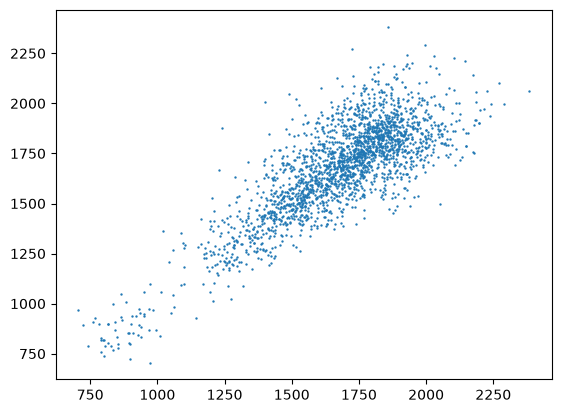

In [54]:
plt.scatter(X,y,s=0.5)

In [56]:
split = int(len(df)*0.8) #we dont shuffle since would like to predict the freq of the current day using the data of the day before, knowing the futur would be "cheating"
X_train, X_test = X.iloc[:split],X.iloc[split:]
y_train, y_test = y.iloc[:split],y.iloc[split:]
model = LinearRegression()
model.fit(X_train,y_train)
print(model.score(X_train,y_train))
y_pred = model.predict(X_test)
y_dumb = X_test["visits_lag1"]

0.6978791384963907


In [60]:
def evaluate(name, y_true, y_hat):
    print(f"{name:10s} MAE={mean_absolute_error(y_true, y_hat):.2f}  "
          f"RMSE={np.sqrt(mean_squared_error(y_true, y_hat)):.2f}  "
          f"R²={r2_score(y_true, y_hat):.3f}")

evaluate("Today=Tomorrow", y_test, y_dumb)
evaluate("LinReg", y_test, y_pred)

print(f"coef={model.coef_[0]:.3f}  intercept={model.intercept_:.2f}")

Today=Tomorrow MAE=100.70  RMSE=135.72  R²=0.234
LinReg     MAE=94.70  RMSE=126.70  R²=0.332
coef=0.836  intercept=275.86
